In [3]:
from pathlib import Path
import pandas as pd
import numpy as np
df = pd.read_csv("E:/american_bankruptcy.csv")

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 78682 entries, 0 to 78681
Data columns (total 21 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   company_name  78682 non-null  object 
 1   status_label  78682 non-null  object 
 2   year          78682 non-null  int64  
 3   X1            78682 non-null  float64
 4   X2            78682 non-null  float64
 5   X3            78682 non-null  float64
 6   X4            78682 non-null  float64
 7   X5            78682 non-null  float64
 8   X6            78682 non-null  float64
 9   X7            78682 non-null  float64
 10  X8            78682 non-null  float64
 11  X9            78682 non-null  float64
 12  X10           78682 non-null  float64
 13  X11           78682 non-null  float64
 14  X12           78682 non-null  float64
 15  X13           78682 non-null  float64
 16  X14           78682 non-null  float64
 17  X15           78682 non-null  float64
 18  X16           78682 non-nu

In [5]:
column_mapping = {
    "X1": "Current Assets",
    "X2": "Cost of Goods Sold",
    "X3": "Depreciation & Amortization",
    "X4": "EBITDA",
    "X5": "Inventory",
    "X6": "Net Income",
    "X7": "Total Receivables",
    "X8": "Market Value",
    "X9": "Net Sales",
    "X10": "Total Assets",
    "X11": "Total Long-term Debt",
    "X12": "EBIT",
    "X13": "Gross Profit",
    "X14": "Total Current Liabilities",
    "X15": "Retained Earnings",
    "X16": "Total Revenue",
    "X17": "Total Liabilities",
    "X18": "Total Operating Expenses",
}

df = df.rename(columns=column_mapping)

In [6]:
df["Return on Assets (%)"] = (df["Net Income"] / df["Total Assets"]) * 100
df["Return on Equity (%)"] = (
    df["Net Income"] / (df["Total Assets"] - df["Total Liabilities"])
) * 100
df["Gross Profit Margin (%)"] = (df["Gross Profit"] / df["Total Revenue"]) * 100
df["Operating Margin (%)"] = (df["EBIT"] / df["Total Revenue"]) * 100
df["Current Ratio"] = df["Current Assets"] / df["Total Current Liabilities"]
df["Debt to Equity Ratio"] = df["Total Liabilities"] / (
    df["Total Assets"] - df["Total Liabilities"]
)


first_year = int(df["year"].min())
last_year = int(df["year"].max())

latest = df[df["year"] == last_year].copy()
earliest = df[df["year"] == first_year].copy()

In [7]:
print(df.columns)

Index(['company_name', 'status_label', 'year', 'Current Assets',
       'Cost of Goods Sold', 'Depreciation & Amortization', 'EBITDA',
       'Inventory', 'Net Income', 'Total Receivables', 'Market Value',
       'Net Sales', 'Total Assets', 'Total Long-term Debt', 'EBIT',
       'Gross Profit', 'Total Current Liabilities', 'Retained Earnings',
       'Total Revenue', 'Total Liabilities', 'Total Operating Expenses',
       'Return on Assets (%)', 'Return on Equity (%)',
       'Gross Profit Margin (%)', 'Operating Margin (%)', 'Current Ratio',
       'Debt to Equity Ratio'],
      dtype='object')


In [ ]:
top_income = latest.sort_values("Net Income", ascending=False).iloc[0]
top_assets = latest.sort_values("Total Assets", ascending=False).iloc[0]
top_market_val = latest.sort_values("Market Value", ascending=False).iloc[0]
top_roa = latest.sort_values("Return on Assets (%)", ascending=False).iloc[0]

report_lines = [
    f"Corporate Financial Performance Summary ({first_year}-{last_year})",
    "=" * 55,
    "",
    f"Dataset Scope: {df['company_name'].nunique()} companies, {first_year}-{last_year}.",
    "",
    f"{last_year} Market Leaders:",
    f"- Net Income Leader: {top_income['company_name']} (${top_income['Net Income']:,.2f}M).",
    f"- Total Assets Leader: {top_assets['company_name']} (${top_assets['Total Assets']:,.2f}M).",
    f"- Market Capitalization Leader: {top_market_val['company_name']} (${top_market_val['Market Value']:,.2f}M).",
    f"- Return on Assets (ROA) Leader: {top_roa['company_name']} ({top_roa['Return on Assets (%)']:.2f}%).",
    "",
    "Interpretation & Takeaways:",
    "- Profitability ratios (ROA & ROE) isolate true operational efficiency independently of company size.",
    "- Balance sheet strength should be analyzed by comparing Current Ratio and Debt-to-Equity across peer groups.",
]

report_text = "\n".join(report_lines)
print(report_text)


Corporate Financial Performance Summary (1999-2018)

Dataset Scope: 8971 companies, 1999-2018.

2018 Market Leaders:
- Net Income Leader: C_102 ($59,531.00M).
- Total Assets Leader: C_1452 ($531,864.00M).
- Market Capitalization Leader: C_102 ($1,073,390.54M).
- Return on Assets (ROA) Leader: C_6467 (1115.35%).

Interpretation & Takeaways:
- Profitability ratios (ROA & ROE) isolate true operational efficiency independently of company size.
- Balance sheet strength should be analyzed by comparing Current Ratio and Debt-to-Equity across peer groups.


609

In [ ]:
#  Solvency & Leverage Risk Indicator (Leverage Ratio)

df["Leverage_Ratio"] = df["Total Liabilities"] / (
    df["Total Assets"] - df["Total Liabilities"]
)

#  Trade Credit Risk Indicator (Receivables to Net Sales)

df["Receivables_to_Sales"] = df["Total Receivables"] / df["Net Sales"]

# 4. Operating Efficiency & Coverage Risk (OpEx to EBITDA)
ebitda_clean = df["EBITDA"].replace(0, np.nan)
df["OpEx_to_EBITDA"] = df["Total Operating Expenses"] / ebitda_clean

# Flag companies with high leverage and low liquidity
df["High_Insolvency_Risk"] = (df["Leverage_Ratio"] > 2.0) & (
    df["Current Ratio"] < 1.0
)

# Flag companies with high receivables relative to sales 
df["Trade_Credit_Warning"] = df["Receivables_to_Sales"] > 0.30




Successfully computed insurance risk metrics and saved to 'insurance_risk_analysis.csv'.


In [10]:
raw_columns = [
    "Current Assets",
    "Cost of Goods Sold",
    "Depreciation & Amortization",
    "EBITDA",
    "Inventory",
    "Net Income",
    "Total Receivables",
    "Market Value",
    "Net Sales",
    "Total Assets",
    "Total Long-term Debt",
    "EBIT",
    "Gross Profit",
    "Total Current Liabilities",
    "Retained Earnings",
    "Total Revenue",
    "Total Liabilities",
    "Total Operating Expenses",
]

# Save financial results without raw columns
df_clean = df.drop(columns=raw_columns, errors="ignore")

# Export both datasets cleanly
df_clean.to_csv("financial_analysis_results.csv", index=False)
df_clean.to_csv("insurance_risk_analysis.csv", index=False)

print(
    "Successfully computed insurance metrics and exported clean CSVs without raw columns!"
)

Successfully computed insurance metrics and exported clean CSVs without raw columns!


=== Optimized Random Forest Performance (Threshold = 0.15) ===
ROC-AUC Score: 0.7182

Classification Report:
               precision    recall  f1-score   support

           0       0.97      0.63      0.76     14692
           1       0.12      0.70      0.20      1044

    accuracy                           0.63     15736
   macro avg       0.54      0.66      0.48     15736
weighted avg       0.91      0.63      0.72     15736



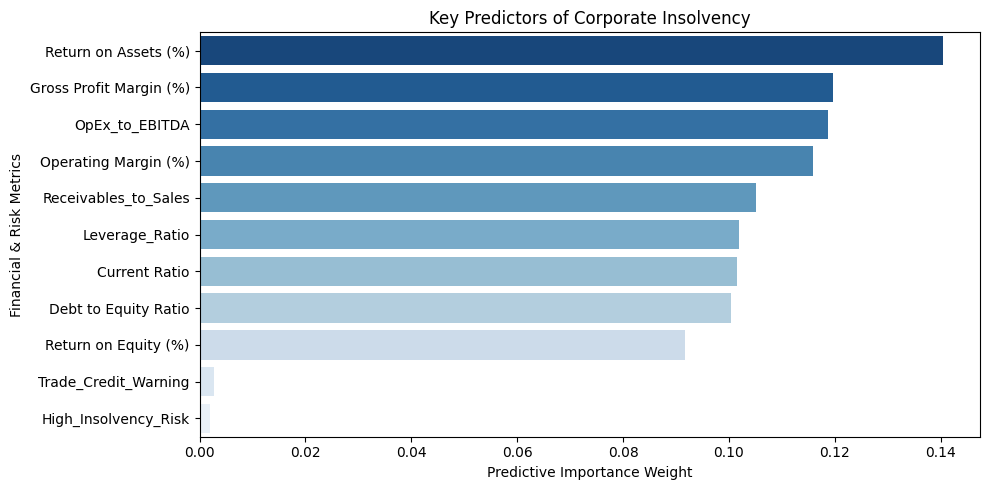

In [14]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.model_selection import train_test_split


feature_cols = [
    "Return on Assets (%)",
    "Return on Equity (%)",
    "Gross Profit Margin (%)",
    "Operating Margin (%)",
    "Current Ratio",
    "Debt to Equity Ratio",
    "Leverage_Ratio",
    "Receivables_to_Sales",
    "OpEx_to_EBITDA",
    "High_Insolvency_Risk",
    "Trade_Credit_Warning",
]

df_ml = df.copy()
df_ml[feature_cols] = df_ml[feature_cols].replace([np.inf, -np.inf], np.nan)
df_ml = df_ml.dropna(subset=feature_cols)


df_ml["target"] = df_ml["status_label"].apply(
    lambda x: 1 if "failed" in str(x).lower() or "bankrupt" in str(x).lower() else 0
)

X = df_ml[feature_cols]
y = df_ml["target"]


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10, 
    class_weight="balanced_subsample",
    random_state=42,
)
rf_model.fit(X_train, y_train)

y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

custom_threshold = 0.40
y_pred_custom = (y_prob_rf >= custom_threshold).astype(int)

print("=== Optimized Random Forest Performance (Threshold = 0.15) ===")
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_prob_rf):.4f}")
print(
    "\nClassification Report:\n",
    classification_report(y_test, y_pred_custom),
)


importances = pd.Series(rf_model.feature_importances_, index=feature_cols).sort_values(
    ascending=False
)

plt.figure(figsize=(10, 5))
sns.barplot(
    x=importances.values,
    y=importances.index,
    hue=importances.index,
    palette="Blues_r",
    legend=False,
)
plt.title("Key Predictors of Corporate Insolvency")
plt.xlabel("Predictive Importance Weight")
plt.ylabel("Financial & Risk Metrics")
plt.tight_layout()
plt.savefig("key_predictors.png", dpi=300, bbox_inches="tight")
plt.show()